# Statistical vs. Machine Learning Methods for Financial Forecasting

## 1. Introduction

This study compares statistical and machine learning methods for predicting next-day SPY ETF log returns using historical market data.


### 1.1 Research Question
**Research question:** Do nonlinear machine learning methods improve out-of-sample forecasting accuracy relative to traditional statistical benchmarks?

### 1.2 Forecasting Approaches
Six forecasting methods are compared:

* Historical mean benchmark
* Ordinary least squares
* Ridge regression
* LASSO regression
* Random forest regression
* Gradient boosting regression

## 2. Data and Exploratory Analysis

### 2.1 Data Source and Description

We use daily historical price and trading volume data for the SPDR S&P 500 ETF Trust (SPY), obtained through the yfinance Python package. The dataset covers January 4, 2010, through September 30, 2026, and contains 4,211 trading-day observations.

The dataset includes daily opening, high, low, and closing prices, along with trading volume. Prices are adjusted for stock splits and dividends using auto_adjust=True.

SPY is selected as a highly liquid ETF tracking the S&P 500 Index, providing a single-asset setting for evaluating short-horizon forecasting methods.

The analysis uses daily adjusted closing prices to construct returns, while historical price and volume information is used to develop predictive features.

In [1099]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

spy = pd.read_csv(
    "data/spy.csv",
    index_col="Date",
    parse_dates=True
)

spy.head()


,Close,High,Low,Open,Volume
Date,,,,,
2010-01-04,84.368950,84.413615,83.014044,83.654275,118944600
2010-01-05,84.592308,84.629533,84.011635,84.316864,111579900
2010-01-06,84.651871,84.860317,84.443424,84.510423,116074400
2010-01-07,85.009216,85.113439,84.257316,84.495541,131091100
2010-01-08,85.292084,85.329309,84.614634,84.785855,126402800


### 2.2 Daily Log Returns
We define the daily log return as

$$
r_t = \log\left(\frac{P_t}{P_{t-1}}\right),
$$

where $P_t$ denotes the adjusted closing price on trading day $t$.

Log returns are used instead of raw prices because they measure relative price changes, are additive across time, and are generally more suitable for statistical modeling of financial time series.

In [1100]:
spy["return"] = np.log(spy["Close"]).diff()
# or alternatively: spy["return"] = np.log(spy["Close"] / spy["Close"].shift(1))
# spy["Close"].diff(1)  # Today minus yesterday
# spy["Close"].diff(5)  # Today minus 5 trading days ago

# Inspect the first observations
spy[["Close", "return"]].head()

,Close,return
Date,,
2010-01-04,84.368950,NaN
2010-01-05,84.592308,0.002644
2010-01-06,84.651871,0.000704
2010-01-07,85.009216,0.004212
2010-01-08,85.292084,0.003322


### 2.3 Time Series Visualization
We examine the adjusted closing price and daily log returns to characterize their temporal behavior.

While adjusted prices exhibit substantial long-term growth, daily returns fluctuate around a relatively stable level. Large positive and negative returns appear concentrated during periods of market turbulence, suggesting volatility clustering.

These observations motivate the inclusion of historical volatility measures in the forecasting models.

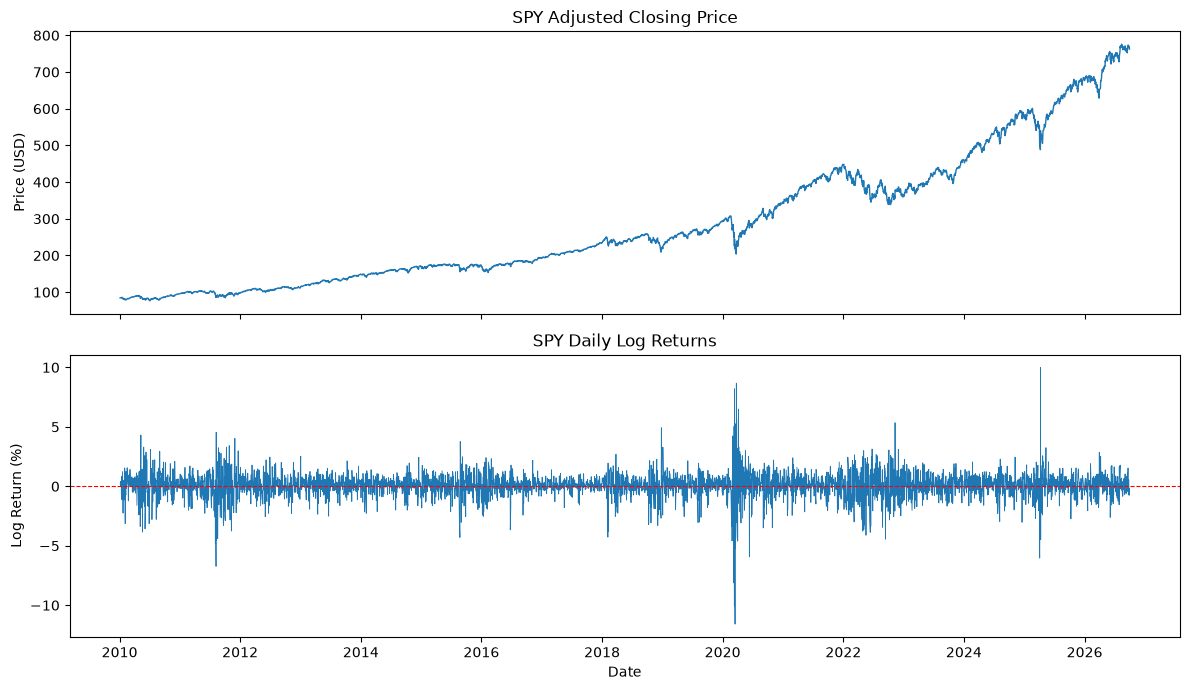

In [1101]:
## comparing this against the raw adjusted closing price: 
fig, axes = plt.subplots(2, 1, figsize=(12, 7), sharex=True)

# Plot 1: Adjusted closing prices
axes[0].plot(spy.index, spy["Close"], linewidth=1)
axes[0].set_title("SPY Adjusted Closing Price")
axes[0].set_ylabel("Price (USD)")

# Plot 2: Daily log returns
axes[1].plot(spy.index, spy["return"] * 100, linewidth=0.6)
axes[1].axhline(0, color="red", linestyle="--", linewidth=0.8)
axes[1].set_title("SPY Daily Log Returns")
axes[1].set_xlabel("Date")
axes[1].set_ylabel("Log Return (%)")

plt.tight_layout()
plt.show()

### 2.4 Descriptive Statistics

We summarize the central tendency, dispersion, skewness, and kurtosis of daily log returns. We also identify the ten largest positive and negative daily returns to investigate whether extreme price movements are concentrated in particular historical periods.

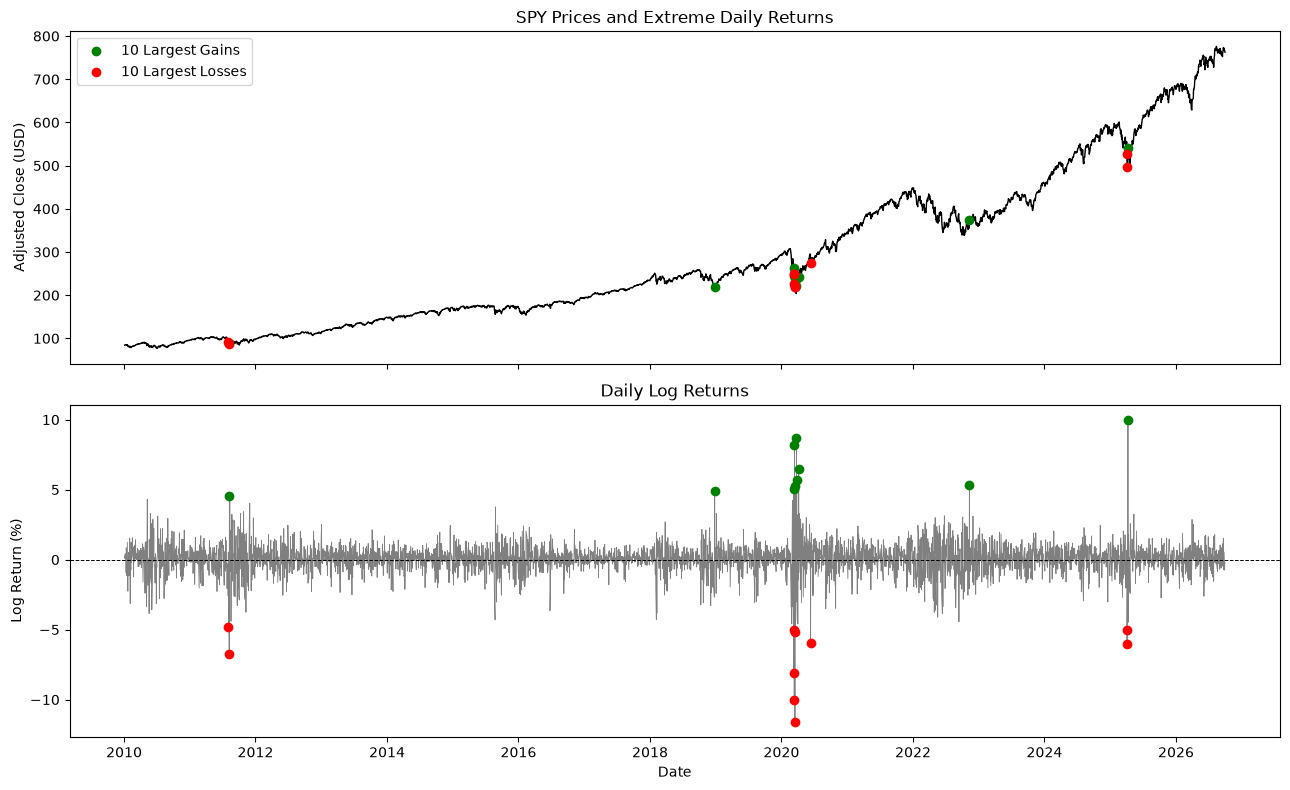

In [1102]:
# Identify the 10 largest daily gains and losses
largest_gains = spy.nlargest(10, "return")
largest_losses = spy.nsmallest(10, "return")

fig, axes = plt.subplots(2, 1, figsize=(13, 8), sharex=True)

# Top: Adjusted closing price
axes[0].plot(spy.index, spy["Close"], color="black", linewidth=1)

axes[0].scatter(
    largest_gains.index, largest_gains["Close"],
    color="green", label="10 Largest Gains", zorder=3
)
axes[0].scatter(
    largest_losses.index, largest_losses["Close"],
    color="red", label="10 Largest Losses", zorder=3
)

axes[0].set_title("SPY Prices and Extreme Daily Returns")
axes[0].set_ylabel("Adjusted Close (USD)")
axes[0].legend()

# Bottom: Daily log returns
axes[1].plot(spy.index, spy["return"] * 100,
             color="gray", linewidth=0.6)

axes[1].scatter(
    largest_gains.index, largest_gains["return"] * 100,
    color="green", zorder=3
)
axes[1].scatter(
    largest_losses.index, largest_losses["return"] * 100,
    color="red", zorder=3
)

axes[1].axhline(0, color="black", linestyle="--", linewidth=0.7)
axes[1].set_title("Daily Log Returns")
axes[1].set_ylabel("Log Return (%)")
axes[1].set_xlabel("Date")

plt.tight_layout()
plt.show()

In [1103]:
# Descriptive statistics of daily log returns
returns = spy["return"].dropna()

summary = pd.Series({
    "Mean": returns.mean(),
    "Std. Dev.": returns.std(),
    "Median": returns.median(),
    "Skewness": returns.skew(),
    "Excess Kurtosis": returns.kurt(),
    "Minimum": returns.min(),
    "Maximum": returns.max()
})

display(summary.to_frame("Value").round(5))

,Value
Mean,0.00052
Std. Dev.,0.01076
Median,0.00069
Skewness,-0.55434
Excess Kurtosis,12.42463
Minimum,-0.11589
Maximum,0.09986


The largest positive and negative daily returns are concentrated in several overlapping periods. To investigate these patterns more closely, we examine three periods of market turbulence: 2011, 2020, and 2022.

For each period, we compare adjusted closing prices, daily log returns, and return volatility.

In [1104]:
extreme = pd.concat([largest_gains, largest_losses])
extreme = extreme.sort_index()

display(
    extreme[["Close", "return"]]
    .assign(return_pct=lambda x: x["return"] * 100)
    [["Close", "return_pct"]]
    .round(3)
)

,Close,return_pct
Date,,
2011-08-04,92.137,-4.797
2011-08-08,86.007,-6.734
2011-08-09,90.007,4.545
2018-12-26,219.682,4.929
2020-03-09,249.347,-8.131
2020-03-10,262.249,5.045
2020-03-11,249.465,-4.998
2020-03-12,225.597,-10.057
2020-03-13,244.882,8.203


In [1105]:
## creating a function to select any date range:
def plot_market_period(spy, start, end):
    period = spy.loc[start:end]

    fig, axes = plt.subplots(2, 1, figsize=(12, 7), sharex=True)

    # Adjusted closing prices
    axes[0].plot(period.index, period["Close"], color="black")
    axes[0].set_title(f"SPY Prices: {start} to {end}")
    axes[0].set_ylabel("Adjusted Close (USD)")

    # Daily returns
    axes[1].bar(
        period.index,
        period["return"] * 100,
        color=[
            "green" if r >= 0 else "red"
            for r in period["return"]
        ]
    )

    axes[1].axhline(0, color="black", linewidth=0.7)
    axes[1].set_ylabel("Daily Log Return (%)")
    axes[1].set_xlabel("Date")

    plt.tight_layout()
    plt.show()


Examining the 2011 market turmoil, the 2020 COVID-19 crash, and the 2022 bear market.

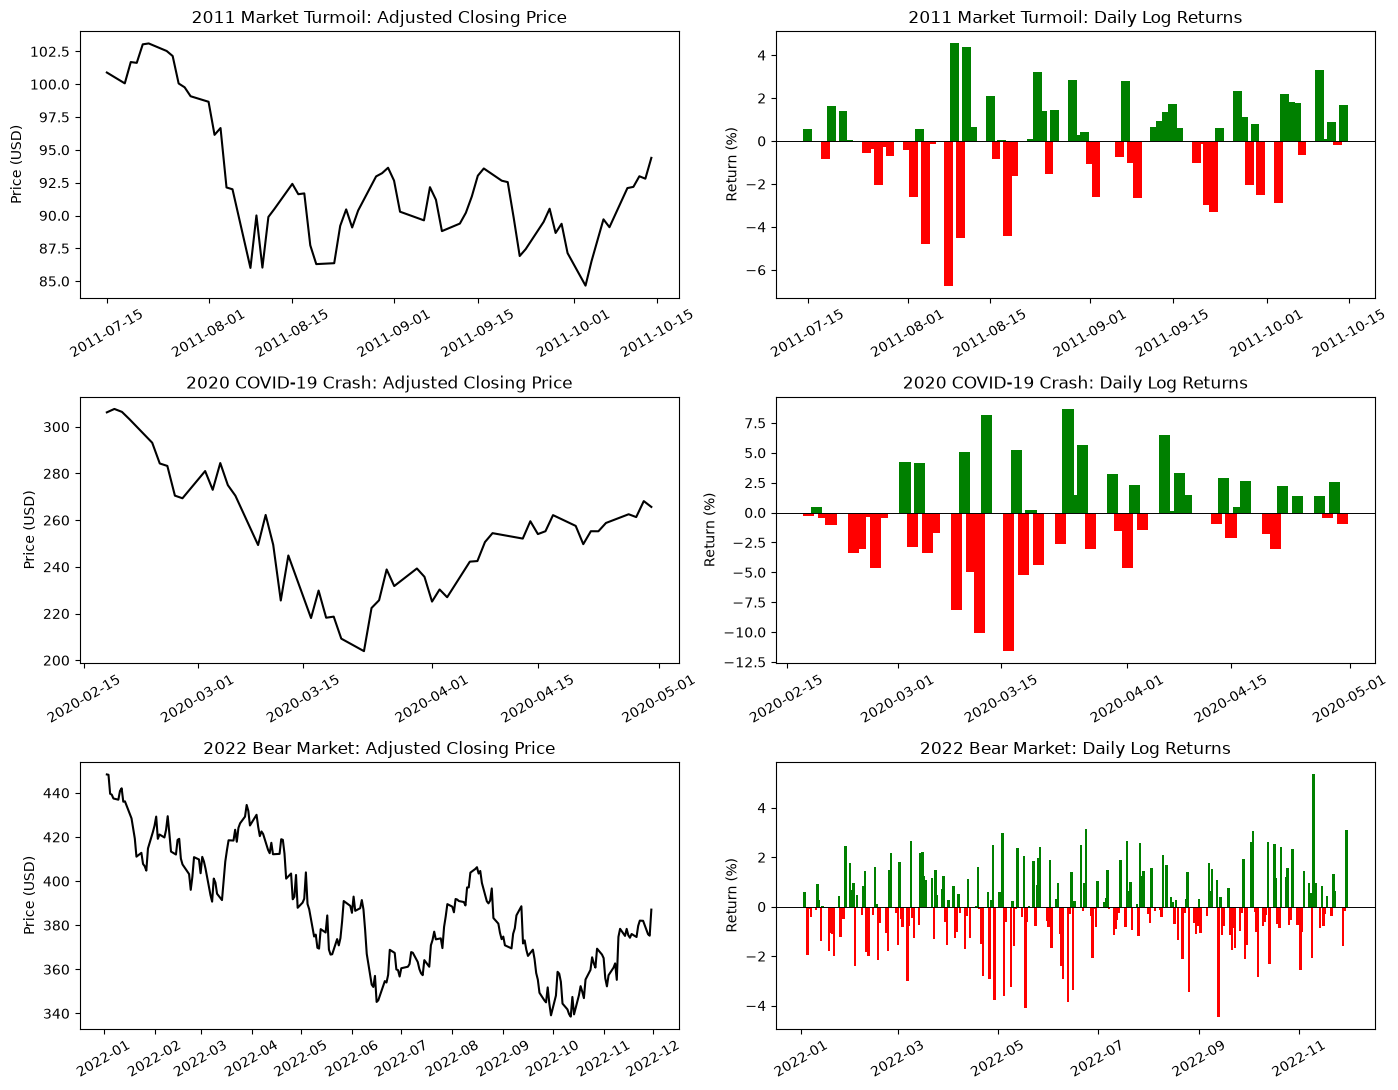

In [1106]:
periods = {
    "2011 Market Turmoil": ("2011-07-15", "2011-10-15"),
    "2020 COVID-19 Crash": ("2020-02-15", "2020-04-30"),
    "2022 Bear Market": ("2022-01-01", "2022-11-30")
}

fig, axes = plt.subplots(3, 2, figsize=(14, 11))

for i, (name, (start, end)) in enumerate(periods.items()):
    period = spy.loc[start:end]

    # Left: adjusted closing price
    axes[i, 0].plot(period.index, period["Close"], color="black")
    axes[i, 0].set_title(f"{name}: Adjusted Closing Price")
    axes[i, 0].set_ylabel("Price (USD)")

    # Right: daily log returns
    axes[i, 1].bar(
        period.index,
        period["return"] * 100,
        color=["green" if r >= 0 else "red"
               for r in period["return"]],
        width=1.5
    )
    axes[i, 1].axhline(0, color="black", linewidth=0.7)
    axes[i, 1].set_title(f"{name}: Daily Log Returns")
    axes[i, 1].set_ylabel("Return (%)")

    for ax in axes[i]:
        ax.tick_params(axis="x", rotation=30)

plt.tight_layout()
plt.show()

Computing the volatility in each period: 

In [1107]:
for name, (start, end) in periods.items():
    r = spy.loc[start:end, "return"].dropna()

    print(f"{name}")
    print(f"  Mean daily return: {r.mean()*100:.3f}%")
    print(f"  Daily volatility:  {r.std()*100:.3f}%")
    print(f"  Largest daily gain: {r.max()*100:.2f}%")
    print(f"  Largest daily loss: {r.min()*100:.2f}%")
    print()

2011 Market Turmoil
  Mean daily return: -0.094%
  Daily volatility:  2.177%
  Largest daily gain: 4.55%
  Largest daily loss: -6.73%

2020 COVID-19 Crash
  Mean daily return: -0.278%
  Daily volatility:  4.114%
  Largest daily gain: 8.67%
  Largest daily loss: -11.59%

2022 Bear Market
  Mean daily return: -0.061%
  Daily volatility:  1.560%
  Largest daily gain: 5.35%
  Largest daily loss: -4.45%



### 2.5 Distribution of Returns
We examine the empirical distribution of daily SPY log returns and compare it with a fitted normal distribution.

In particular, we investigate whether returns exhibit skewness, heavy tails, or other departures from normality. These characteristics are relevant to understanding extreme market movements and evaluating forecasting models.

*Step 1.* Histogram with fitted normal density
We first estimate the mean and standard deviation of the observed returns:

$$
\hat{\mu} = \frac{1}{n}\sum_{t=1}^{n} r_t,
\qquad
\hat{\sigma} = \sqrt{\frac{1}{n-1}\sum_{t=1}^{n}(r_t-\hat{\mu})^2}.
$$

We then compare the empirical distribution of returns with a fitted normal distribution:

$$
r_t \sim N(\hat{\mu}, \hat{\sigma}^2).
$$

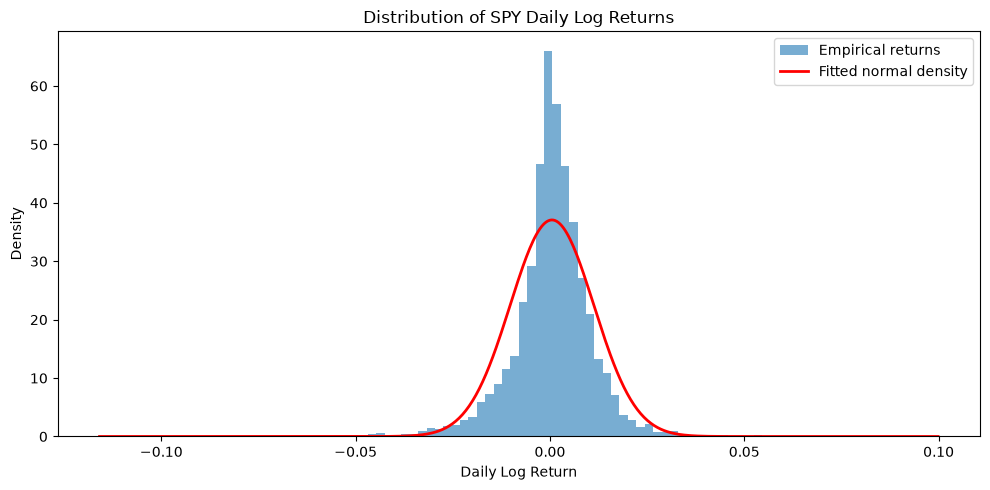

In [1108]:
from scipy.stats import norm, t

returns = spy["return"].dropna()

mu = returns.mean()
sigma = returns.std()

# Values for the fitted normal density
x = np.linspace(returns.min(), returns.max(), 500)
normal_density = norm.pdf(x, loc=mu, scale=sigma)

plt.figure(figsize=(10, 5))

plt.hist(
    returns,
    bins=100,
    density=True,
    alpha=0.6,
    label="Empirical returns"
)

plt.plot(
    x, normal_density,
    color="red",
    linewidth=2,
    label="Fitted normal density"
)

plt.title("Distribution of SPY Daily Log Returns")
plt.xlabel("Daily Log Return")
plt.ylabel("Density")
plt.legend()

plt.tight_layout()
plt.show()

The empirical return distribution is more sharply concentrated near zero than the fitted normal distribution. This suggests that a single normal distribution may inadequately represent both the concentration of small returns and the occurrence of extreme observations.

*Step 2.* Normal Q-Q Plot

The histogram doesn't show the deviations in the tails. Using a Q-Q plot to check the fit:

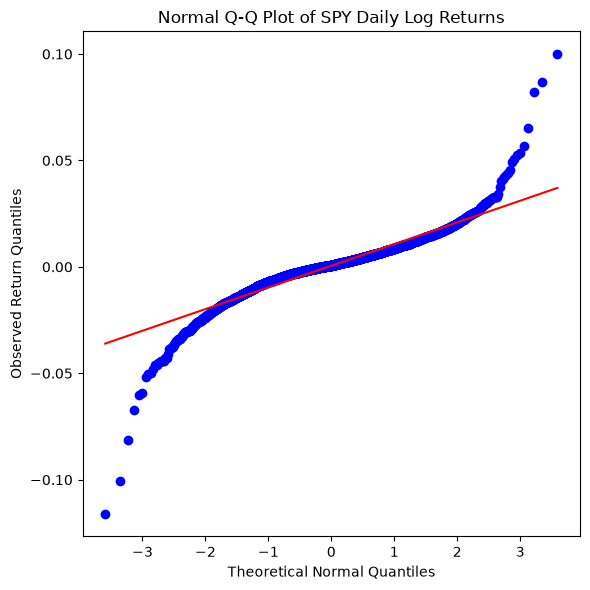

In [1109]:
from scipy import stats

fig, ax = plt.subplots(figsize=(6, 6))

stats.probplot(returns, dist="norm", plot=ax)

ax.set_title("Normal Q-Q Plot of SPY Daily Log Returns")
ax.set_xlabel("Theoretical Normal Quantiles")
ax.set_ylabel("Observed Return Quantiles")

plt.tight_layout()
plt.show()

The normal Q-Q plot reveals substantial departures from normality in both tails. The lower empirical quantiles fall below the theoretical normal reference line, while the upper quantiles rise above it, indicating more extreme negative and positive returns than predicted by the fitted normal distribution.

The central quantiles lie comparatively close to the reference line, although some curvature remains evident.

*Step 3.* Quantify how heavy the tails are

In [1110]:
# Distributional summary and tail-frequency comparison
returns = spy["return"].dropna()

mu = returns.mean()
sigma = returns.std()

z = (returns - mu) / sigma

empirical_tail = (z.abs() > 3).mean()
normal_tail = 2 * stats.norm.sf(3)

distribution_summary = pd.DataFrame({
    "Statistic": [
        "Skewness",
        "Excess Kurtosis",
        "Empirical P(|Z| > 3)",
        "Normal P(|Z| > 3)",
        "Tail Frequency Ratio"
    ],
    "Value": [
        returns.skew(),
        returns.kurt(),
        empirical_tail,
        normal_tail,
        empirical_tail / normal_tail
    ]
})

display(distribution_summary.round(4))

,Statistic,Value
0,Skewness,-0.5543
1,Excess Kurtosis,12.4246
2,Empirical P(|Z| > 3),0.0143
3,Normal P(|Z| > 3),0.0027
4,Tail Frequency Ratio,5.2788


The empirical distribution exhibits negative skewness (−0.554) and substantial excess kurtosis (12.425), indicating asymmetry and pronounced tail extremity.

Approximately 1.425% of daily log returns exceed three sample standard deviations in absolute value, compared with 0.270% under the fitted normal benchmark. Thus, extreme standardized returns occur approximately 5.28 times as frequently as predicted by normality.

These findings suggest that a normal distribution is inadequate for describing the unconditional tail behavior of daily SPY returns.

### 2.6 Parametric Distribution Fitting

The exploratory analysis indicates that daily SPY log returns exhibit negative skewness, substantial excess kurtosis, and heavy tails relative to a normal distribution.

We compare three candidate parametric models for the unconditional return distribution:

Normal distribution: A baseline model with symmetric, light-tailed behavior.

Student's (t) distribution: A symmetric distribution allowing heavier tails.

Two-component Gaussian mixture: A flexible mixture that can accommodate different levels of dispersion and asymmetric behavior.

Parameters are estimated by maximum likelihood. We compare the fitted distributions using AIC, BIC, and the calibration of extreme-return probabilities.

These comparisons describe unconditional returns and do not explicitly account for time-varying volatility or temporal dependence.

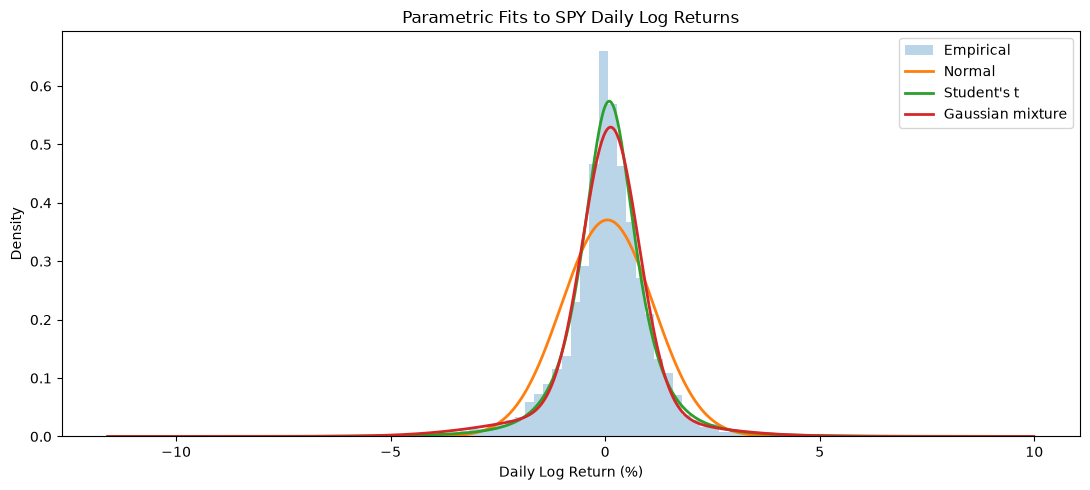

Student's t degrees of freedom: 2.781
Mixture weights: [0.80014787 0.19985213]
Mixture means: [ 0.13038689 -0.26036691]
Mixture standard deviations: [0.65103831 1.99346489]


In [1111]:
from sklearn.mixture import GaussianMixture

returns = spy["return"].dropna().to_numpy()

# Scale returns to percentage units for numerical stability
r = returns * 100

# 1. Fit normal
mu_n, sd_n = stats.norm.fit(r)

# 2. Fit Student's t
df_t, loc_t, scale_t = stats.t.fit(r)

# 3. Fit two-component Gaussian mixture
gmm = GaussianMixture(
    n_components=2,
    random_state=42,
    n_init=10
)
gmm.fit(r.reshape(-1, 1))

# Compare fitted densities
x = np.linspace(r.min(), r.max(), 1000)

normal_pdf = stats.norm.pdf(x, mu_n, sd_n)
t_pdf = stats.t.pdf(x, df_t, loc_t, scale_t)
mixture_pdf = np.exp(gmm.score_samples(x.reshape(-1, 1)))

plt.figure(figsize=(11, 5))

plt.hist(r, bins=100, density=True, alpha=0.3, label="Empirical")
plt.plot(x, normal_pdf, label="Normal", linewidth=2)
plt.plot(x, t_pdf, label="Student's t", linewidth=2)
plt.plot(x, mixture_pdf, label="Gaussian mixture", linewidth=2)

plt.xlabel("Daily Log Return (%)")
plt.ylabel("Density")
plt.title("Parametric Fits to SPY Daily Log Returns")
plt.legend()
plt.tight_layout()
plt.show()

print(f"Student's t degrees of freedom: {df_t:.3f}")
print(f"Mixture weights: {gmm.weights_}")
print(f"Mixture means: {gmm.means_.ravel()}")
print(f"Mixture standard deviations: {np.sqrt(gmm.covariances_.ravel())}")

In [1112]:
########## Assessing these fits

n = len(r)

# Log-likelihoods
ll_normal = stats.norm.logpdf(r, mu_n, sd_n).sum()

ll_t = stats.t.logpdf(
    r, df_t, loc=loc_t, scale=scale_t
).sum()

ll_gmm = gmm.score_samples(r.reshape(-1, 1)).sum()

# Number of estimated parameters
models = {
    "Normal": (ll_normal, 2),
    "Student's t": (ll_t, 3),
    "Gaussian Mixture": (ll_gmm, 5)
}

comparison = pd.DataFrame([
    {
        "Model": name,
        "Log-Likelihood": ll,
        "AIC": -2 * ll + 2 * k,
        "BIC": -2 * ll + k * np.log(n)
    }
    for name, (ll, k) in models.items()
])

display(comparison.sort_values("BIC").round(2))

,Model,Log-Likelihood,AIC,BIC
1,Student's t,-5685.83,11377.66,11396.69
2,Gaussian Mixture,-5738.14,11486.28,11518.01
0,Normal,-6282.07,12568.14,12580.83


In [1113]:
########## Assessing the tail calibration

# Thresholds in percentage-return units
lower = r.mean() - 3 * r.std(ddof=1)
upper = r.mean() + 3 * r.std(ddof=1)

# Empirical probability
empirical = np.mean((r < lower) | (r > upper))

# Normal probability
p_normal = (
    norm.cdf(lower, mu_n, sd_n)
    + norm.sf(upper, mu_n, sd_n)
)

# Student's t probability
p_t = (
    t.cdf(lower, df_t, loc_t, scale_t)
    + t.sf(upper, df_t, loc_t, scale_t)
)

# Gaussian mixture probability
weights = gmm.weights_
means = gmm.means_.ravel()
sds = np.sqrt(gmm.covariances_.ravel())

p_gmm = np.sum(
    weights * (
        norm.cdf(lower, loc=means, scale=sds)
        + norm.sf(upper, loc=means, scale=sds)
    )
)

tail_table = pd.DataFrame({
    "Model": ["Empirical", "Normal", "Student's t", "Gaussian Mixture"],
    "P(|r - mean| > 3 SD)": [empirical, p_normal, p_t, p_gmm]
})

display(tail_table.round(5))

,Model,P(|r - mean| > 3 SD)
0,Empirical,0.01425
1,Normal,0.00270
2,Student's t,0.01774
3,Gaussian Mixture,0.02191


**Distribution Fit Assessment**

Among the three candidate distributions, Student's (t) provides the strongest in-sample fit, achieving the lowest AIC (11,377.66) and BIC (11,396.69). Its estimated degrees of freedom, (\hat{\nu}=2.781), indicate substantial tail heaviness.

The empirical frequency of returns exceeding three sample standard deviations in absolute value is 1.425%. The fitted normal distribution substantially underestimates this frequency (0.270%), while Student's (t) (1.774%) and the Gaussian mixture (2.191%) provide closer approximations.

Student's (t) achieves the closest calibration at this particular threshold, although it slightly overestimates the observed frequency. Its symmetric specification, however, cannot explicitly capture the negative skewness observed in the data.

Overall, Student's (t) emerges as the preferred parsimonious model among the three candidates based on in-sample likelihood criteria and the selected tail-calibration measure.

These results do not establish out-of-sample predictive superiority. Furthermore, none of the fitted distributions explicitly accounts for temporal changes in volatility, which may contribute to the heavy-tailed unconditional return distribution.

The subsequent analysis focuses on whether historical market information can improve forecasts of next-day returns.

## 3. Feature Engineering

The goal is to transform the historical data into a dataset containing predictors X and a target variable Y. 

### 3.1 Prediction Target

We formulate next-day SPY return forecasting as a supervised regression problem. Let (X_t) denote the predictor vector constructed from market information available through trading day (t).

The prediction target is the next-day log return:

$$
Y_t = r_{t+1} = \log\left(\frac{P_{t+1}}{P_t}\right).
$$

Our objective is to estimate the conditional mean:

$$
E[Y_t \mid X_t].
$$

All predictors are constructed using only information available at the forecast origin to avoid look-ahead bias.

In [1114]:
# Create the next-day return target
spy["target"] = spy["return"].shift(-1)

display(spy[["Close", "return", "target"]].head())

,Close,return,target
Date,,,
2010-01-04,84.368950,NaN,0.002644
2010-01-05,84.592308,0.002644,0.000704
2010-01-06,84.651871,0.000704,0.004212
2010-01-07,85.009216,0.004212,0.003322
2010-01-08,85.292084,0.003322,0.001396


### 3.2 Lagged Returns

We include the current and four preceding daily log returns as predictors to investigate whether historical returns contain information about next-day returns.

$$
X_t^{\mathrm{lag}}=(r_t,r_{t-1},r_{t-2},r_{t-3},r_{t-4}).
$$

These features allow the forecasting models to capture potential short-term serial dependence in returns.

In [1115]:
for lag in range(5):
    spy[f"return_lag{lag}"] = spy["return"].shift(lag)

columns = ["return", "target"] + [
    f"return_lag{i}" for i in range(5)
]

display(spy[columns].head(10))

,return,target,return_lag0,return_lag1,return_lag2,return_lag3,return_lag4
Date,,,,,,,
2010-01-04,NaN,0.002644,NaN,NaN,NaN,NaN,NaN
2010-01-05,0.002644,0.000704,0.002644,NaN,NaN,NaN,NaN
2010-01-06,0.000704,0.004212,0.000704,0.002644,NaN,NaN,NaN
2010-01-07,0.004212,0.003322,0.004212,0.000704,0.002644,NaN,NaN
2010-01-08,0.003322,0.001396,0.003322,0.004212,0.000704,0.002644,NaN
2010-01-11,0.001396,-0.009370,0.001396,0.003322,0.004212,0.000704,0.002644
2010-01-12,-0.009370,0.008410,-0.009370,0.001396,0.003322,0.004212,0.000704
2010-01-13,0.008410,0.002701,0.008410,-0.009370,0.001396,0.003322,0.004212
2010-01-14,0.002701,-0.011288,0.002701,0.008410,-0.009370,0.001396,0.003322


### 3.3 Rolling Volatility and Momentum

**Definition:** Rolling volatility measures how much returns have fluctuated over a recent window of time. Rather than calculating one standard deviation using the entire historical dataset, we calculate a new standard deviation every trading day using only the most recent observations.


Suppose we use a 20-trading-day rolling window.

At time $t$, rolling volatility is defined as


$$
\hat{\sigma}_{t,20}
=
\sqrt{
\frac{1}{19}
\sum_{i=0}^{19}
(r_{t-i}-\bar{r}_{t,20})^2
}
$$

where

$$
\bar{r}_{t,20}
=
\frac{1}{20}\sum_{i=0}^{19}r_{t-i}.
$$

This is the sample standard deviation of the most recent 20 daily log returns, including the return observed on day $t$.


Since our target is the next day's return, rolling volatility becomes one of the predictors. While rolling volatility may be highly informative about the magnitude of tomorrow's return, it may not be informative about its sign.

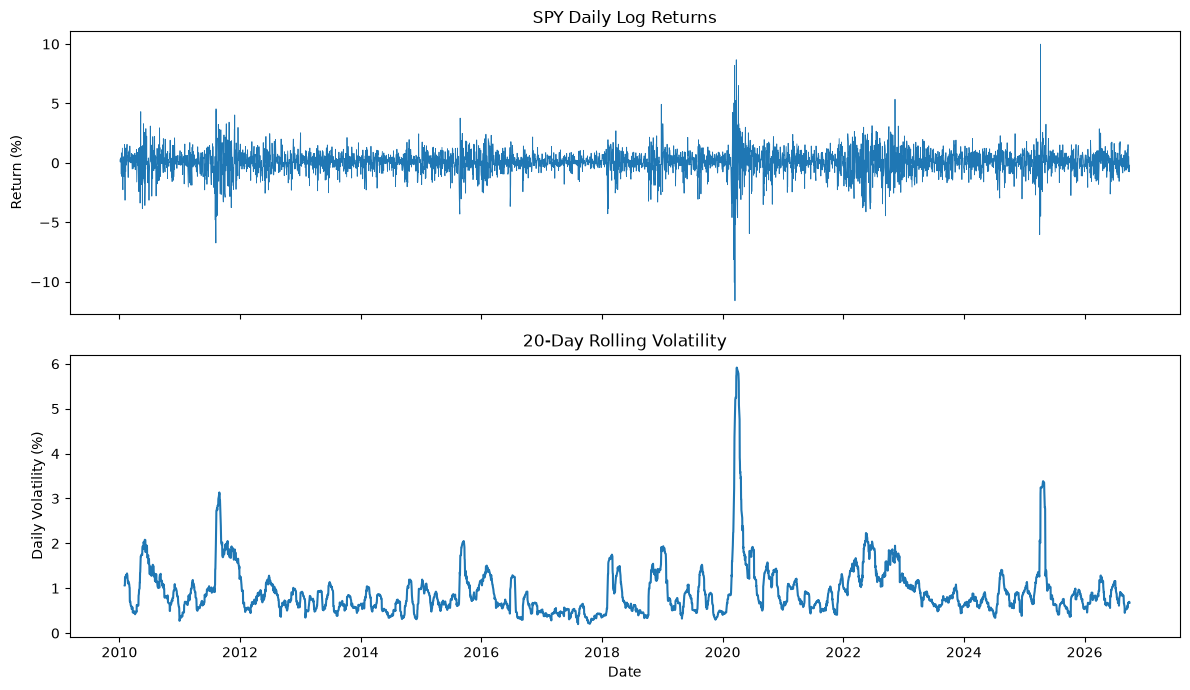

In [1116]:
# .rolling(window=20) selects the current observation and the previous 19 trading days.

spy["volatility_20"] = spy["return"].rolling(window=20).std()

# visualizing 
fig, axes = plt.subplots(2, 1, figsize=(12, 7), sharex=True)

axes[0].plot(spy.index, spy["return"] * 100, linewidth=0.6)
axes[0].set_title("SPY Daily Log Returns")
axes[0].set_ylabel("Return (%)")

axes[1].plot(spy.index, spy["volatility_20"] * 100)
axes[1].set_title("20-Day Rolling Volatility")
axes[1].set_ylabel("Daily Volatility (%)")
axes[1].set_xlabel("Date")

plt.tight_layout()
plt.show()

**Definition:** Momentum measures how much an asset's price has increased or decreased over a recent period. In finance, it's used to investigate whether past price trends contain information about future returns.

In [ ]:
# 5-day cumulative log return
spy["momentum_5"] = spy["return"].rolling(window=5).sum()

# 20-day cumulative log return
spy["momentum_20"] = spy["return"].rolling(window=20).sum()

display(
    spy[["return", "volatility_20",
         "momentum_5", "momentum_20"]].tail(10)
)

,return,volatility_20,momentum_5,momentum_20
Date,,,,
2026-09-17,0.011275,0.006063,0.006275,-0.008435
2026-09-18,0.001286,0.005769,-0.000927,0.001286
2026-09-21,0.015386,0.006667,0.018930,0.012589
2026-09-22,-0.000155,0.006618,0.023372,0.015377
2026-09-23,-0.007228,0.006824,0.020564,0.004958
2026-09-24,-0.000821,0.006828,0.008468,0.003915
2026-09-25,0.005421,0.006778,0.012603,0.002804
2026-09-28,-0.007469,0.006972,-0.010253,-0.002393
2026-09-29,-0.001843,0.006952,-0.011941,-0.001242


## 4. Experimental Design

### 4.1 Chronological Data Split

### 4.2 Time-Series Cross-Validation

### 4.3 Preventing Look-Ahead Bias

## 5. Forecasting Models

### 5.1 Historical Mean Benchmark

### 5.2 Ordinary Least Squares

### 5.3 Ridge and LASSO Regression

### 5.4 Random Forest

### 5.5 Gradient Boosting

## 6. Out-of-Sample Evaluation

### 6.1 Performance Metrics

### 6.2 Model Comparison

### 6.3 Prediction Diagnostics

## 7. Discussion and Conclusions

### 7.1 Main Findings

### 7.2 Limitations

### 7.3 Conclusion